# PROYECTO PARCIAL I - PREDICCIÓN DEL RENDIMIENTO ACADÉMICO
**Integrantes:**
- CAROLINE YOMAIRA PUYA GOMEZ
-


**GRUPO:** D

**Fecha:** 25/11/26



In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cargamos el dataset directamente desde el repositorio de UCI (para no tener que subir el archivo manualmente)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip"
!wget {url} -O student.zip
!unzip -o student.zip

# Leemos el archivo de matemáticas (student-mat.csv).
df = pd.read_csv('student-mat.csv', sep=';')

# Mostramos las primeras 5 filas para ver que cargó bien
df.head()

--2026-11-26 03:09:04--  https://archive.ics.uci.edu/ml/machine-learning-databases/00320/student.zip
Resolving archive.ics.uci.edu (archive.ics.uci.edu)... 128.195.10.252
Connecting to archive.ics.uci.edu (archive.ics.uci.edu)|128.195.10.252|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified
Saving to: ‘student.zip’

student.zip             [ <=>                ]  20.00K  --.-KB/s    in 0.05s   

2026-11-26 03:09:05 (415 KB/s) - ‘student.zip’ saved [20478]

Archive:  student.zip
  inflating: student-mat.csv         
  inflating: student-por.csv         
  inflating: student-merge.R         
  inflating: student.txt             


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [2]:
# 1. Estructura del dataset
print(" ESTRUCTURA DEL DATASET ")
print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")
print("\n INFORMACIÓN DE TIPOS DE DATOS ")
df.info()
print("\n--- ESTADÍSTICAS DESCRIPTIVAS ---")
display(df.describe())

 ESTRUCTURA DEL DATASET 
Filas: 395
Columnas: 33

 INFORMACIÓN DE TIPOS DE DATOS 
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activiti

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000


El dataset cuenta con 395 estudiantes y 33 variables. Al revisar las estadísticas descriptivas, observamos que la nota final  tiene una media de 10.4 sobre 20 y una desviación estándar de 4.6. Esto nos indica que las notas están muy dispersas, habiendo estudiantes con 0 y otros con calificaciones perfectas de 20.

/tmp/ipykernel_536/780577688.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='failures', y='G3', data=df, palette='Set2')
/tmp/ipykernel_536/780577688.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='studytime', y='G3', data=df, palette='Set3')


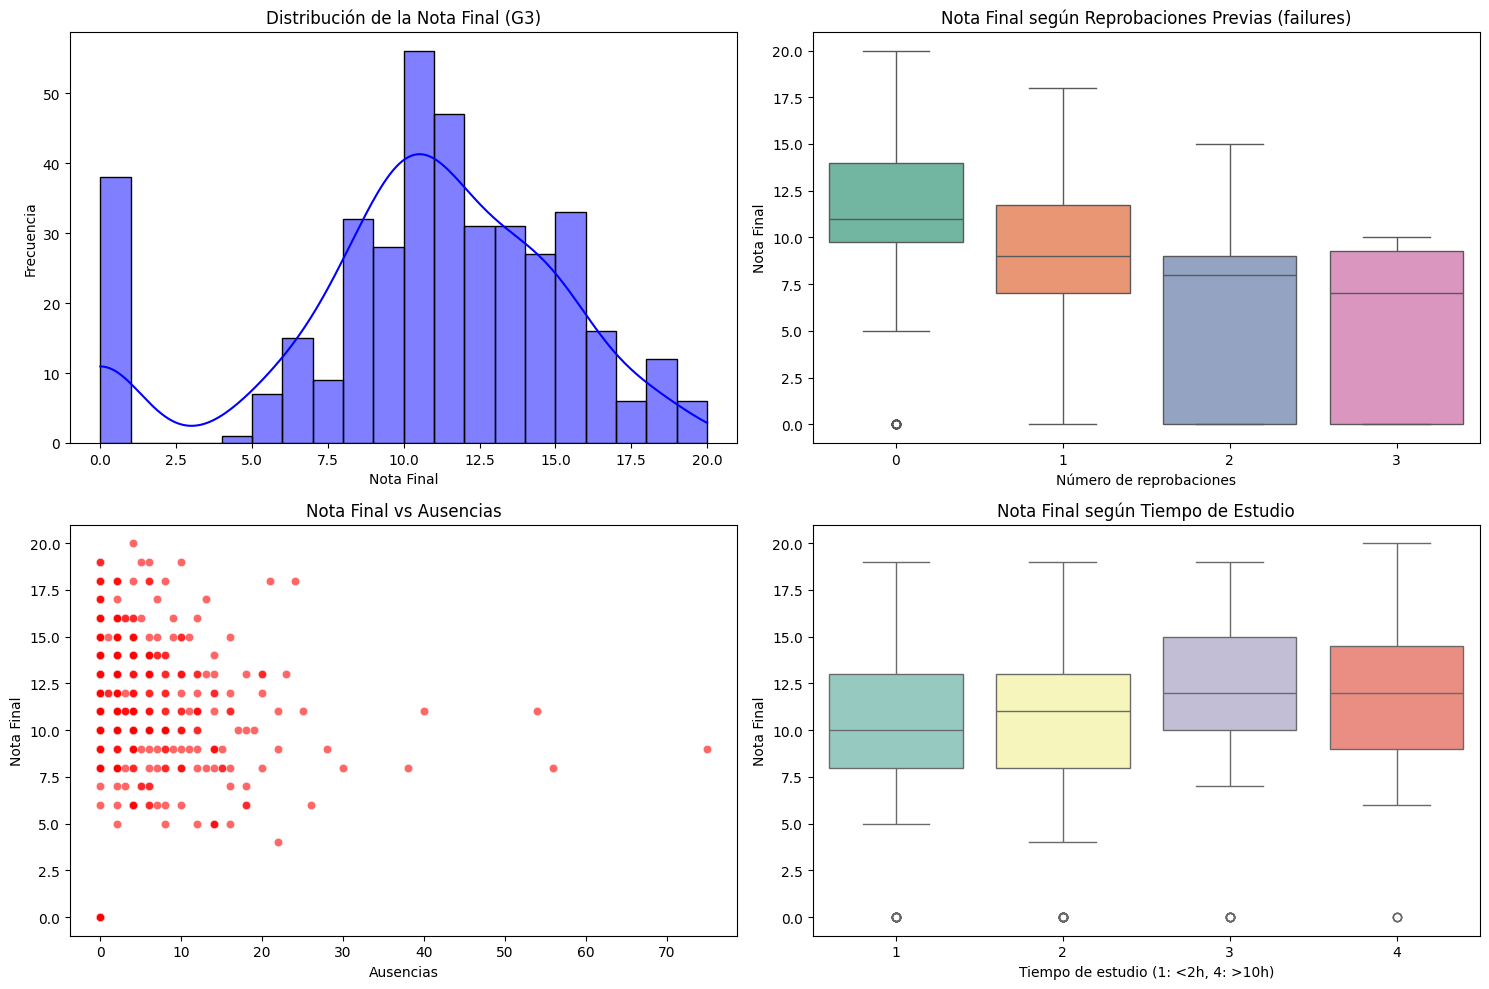

In [3]:
# 2. Gráficos
plt.figure(figsize=(15, 10))

# Gráfico 1: Distribución de G3
plt.subplot(2, 2, 1)
sns.histplot(df['G3'], bins=20, kde=True, color='blue')
plt.title('Distribución de la Nota Final (G3)')
plt.xlabel('Nota Final')
plt.ylabel('Frecuencia')

# Gráfico 2: Boxplot de G3 según reprobaciones previas
plt.subplot(2, 2, 2)
sns.boxplot(x='failures', y='G3', data=df, palette='Set2')
plt.title('Nota Final según Reprobaciones Previas (failures)')
plt.xlabel('Número de reprobaciones')
plt.ylabel('Nota Final')

# Gráfico 3: Dispersión de G3 vs Ausencias
plt.subplot(2, 2, 3)
sns.scatterplot(x='absences', y='G3', data=df, alpha=0.6, color='red')
plt.title('Nota Final vs Ausencias')
plt.xlabel('Ausencias')
plt.ylabel('Nota Final')

# Gráfico 4: Boxplot de G3 según Tiempo de Estudio
plt.subplot(2, 2, 4)
sns.boxplot(x='studytime', y='G3', data=df, palette='Set3')
plt.title('Nota Final según Tiempo de Estudio')
plt.xlabel('Tiempo de estudio (1: <2h, 4: >10h)')
plt.ylabel('Nota Final')

plt.tight_layout()
plt.show()

En el gráfico de boxplot se observa claramente que los estudiantes que no han reprobado ninguna materia antes tienen una mediana de nota final mucho más alta  que aquellos que han reprobado 1, 2 o 3 veces, cuyas medianas caen por debajo de 8. Esto sugiere que el historial de reprobaciones es un predictor muy fuerte del fracaso futuro.
 En el gráfico de dispersión de ausencias vs nota final, no se observa una línea clara. Hay estudiantes con muchas ausencias que sacan notas altas, y estudiantes con pocas ausencias que sacan notas bajas. La ausencia por sí sola no parece ser el factor determinante.

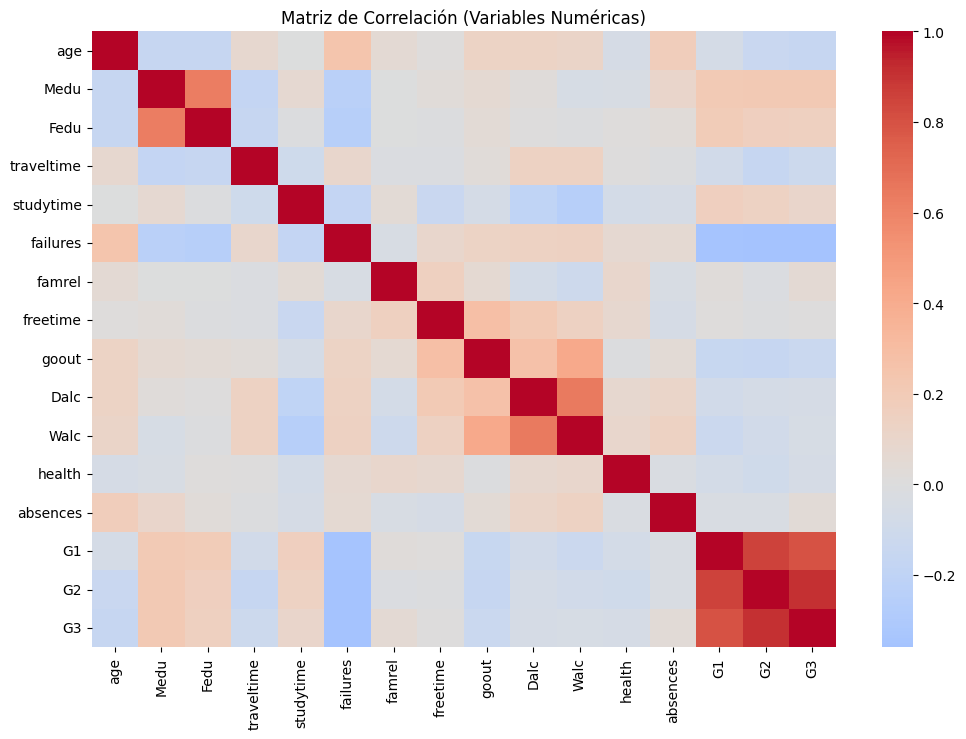


--- VARIABLES MÁS CORRELACIONADAS CON G3 ---
G3            1.000000
G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


In [4]:
# 3. Matriz de correlación
plt.figure(figsize=(12, 8))
# Las columnas numéricas
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

# Graficamos el mapa de calor
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0)
plt.title('Matriz de Correlación (Variables Numéricas)')
plt.show()

# Mostramos las correlaciones respecto a G3 ordenadas
print("\n--- VARIABLES MÁS CORRELACIONADAS CON G3 ---")
print(corr_matrix['G3'].sort_values(ascending=False))

Las variables más relacionadas con G3 son G2 (0.90) y G1 (0.80). Es lógico porque son notas de períodos previos. Si miramos las variables que no son notas, la variable failures  tiene una correlación negativa de -0.36 a más reprobaciones, menor nota, seguida del consumo de alcohol (Dalc con -0.20).